# Customer Summary Data Analysis - EDA using Pandas

**Name:** Aman Rawat  |  **Roll No:** 2501060006  |  **Course:** BCA (AI-DS)  |  **College:** K.R. Mangalam University

This notebook has two parts:
1. **Part A - Project EDA** on the Customer Summary dataset (127,486 transactions, 2016-2022) used for the IBM Cognos dashboard: KPIs and the main charts, done with pandas and matplotlib.
2. **Part B - Pandas DataFrame operations** on a small 15-row sample dataset (10 operations and 5 charts), the same as in the handwritten file.

> **How to run Part A:** put the dataset file (`.csv` or `.xlsx`) in the same folder as this notebook, set `DATA_FILE` in the first code cell of Part A, then use *Kernel > Restart & Run All*. Save the notebook before committing it to GitHub so the outputs are visible.

# Part A - Project EDA (Customer Summary dataset)

## 1. Import libraries

In [ ]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Load the dataset

In [ ]:
DATA_FILE = "customer_summary.csv"   # change to your file name (.csv or .xlsx)

if not os.path.exists(DATA_FILE):
    found = glob.glob("*.csv") + glob.glob("*.xlsx")
    if not found:
        raise FileNotFoundError("Put the dataset file in this folder and set DATA_FILE.")
    DATA_FILE = found[0]

if DATA_FILE.lower().endswith(".csv"):
    sales = pd.read_csv(DATA_FILE)
else:
    sales = pd.read_excel(DATA_FILE)

# make column names uniform: UPPER_CASE_WITH_UNDERSCORES
sales.columns = sales.columns.str.strip().str.upper().str.replace(" ", "_")

print("File:", DATA_FILE)
print("Rows, columns:", sales.shape)
sales.head()

## 3. Check that the required columns exist

In [ ]:
required = ["LOYALTY_NBR", "COUNTRY", "PRODUCT_LINE", "LOYALTY_STATUS", "ORDER_YEAR",
            "QUARTER", "REVENUE", "QUANTITY_SOLD", "INCOME", "SATISFACTION_RATING",
            "SHIPPING_DAYS"]
missing_cols = [c for c in required if c not in sales.columns]
print("Missing columns:", missing_cols if missing_cols else "none")

## 4. Data understanding and data preparation

In [ ]:
sales.info()

In [ ]:
sales.describe()

In [ ]:
print("Missing values per column (only columns that have any):")
miss = sales.isnull().sum()
print(miss[miss > 0] if (miss > 0).any() else "No missing values")
print()
print("Duplicate rows:", sales.duplicated().sum())

## 5. Key Performance Indicators (KPIs)

In [ ]:
total_revenue = sales["REVENUE"].sum()
unique_customers = sales["LOYALTY_NBR"].nunique()
avg_satisfaction = sales["SATISFACTION_RATING"].mean()
avg_shipping = sales["SHIPPING_DAYS"].mean()

print(f"Total transactions   : {len(sales):,}")
print(f"Total revenue        : ${total_revenue:,.0f}")
print(f"Unique customers     : {unique_customers:,}")
print(f"Avg satisfaction     : {avg_satisfaction:.2f}")
print(f"Avg shipping (days)  : {avg_shipping:.1f}")

## 6. Revenue by product line

In [ ]:
by_product = sales.groupby("PRODUCT_LINE")["REVENUE"].sum().sort_values()
by_product.plot(kind="barh", color="#6A29C3")
plt.title("Revenue by Product Line")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()
print((by_product / by_product.sum() * 100).round(1).sort_values(ascending=False))

## 7. Revenue by country

In [ ]:
by_country = sales.groupby("COUNTRY")["REVENUE"].sum().sort_values()
by_country.plot(kind="barh", color="#1F3864")
plt.title("Revenue by Country")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()
print((by_country / by_country.sum() * 100).round(1).sort_values(ascending=False))

## 8. Revenue trend by order year

In [ ]:
by_year = sales.groupby("ORDER_YEAR")["REVENUE"].sum()
plt.plot(by_year.index, by_year.values, marker="o", color="#6A29C3")
plt.title("Revenue Trend by Order Year")
plt.xlabel("Order Year")
plt.ylabel("Revenue")
plt.show()
print("Peak year:", by_year.idxmax(), "with revenue", f"{by_year.max():,.0f}")

## 9. Revenue share by loyalty status

In [ ]:
by_loyalty = sales.groupby("LOYALTY_STATUS")["REVENUE"].sum()
plt.pie(by_loyalty.values, labels=by_loyalty.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share by Loyalty Status")
plt.show()

## 10. Distribution of satisfaction rating

In [ ]:
sales["SATISFACTION_RATING"].plot(kind="hist", bins=7, edgecolor="black", color="#5C8A2E")
plt.title("Distribution of Satisfaction Rating")
plt.xlabel("Satisfaction Rating")
plt.ylabel("Number of Transactions")
plt.show()

## 11. Heat map: revenue by product line and quarter

In [ ]:
heat = sales.pivot_table(values="REVENUE", index="PRODUCT_LINE",
                         columns="QUARTER", aggfunc="sum")
plt.imshow(heat.values, cmap="YlOrRd", aspect="auto")
plt.colorbar(label="Revenue")
plt.xticks(range(len(heat.columns)), heat.columns)
plt.yticks(range(len(heat.index)), heat.index)
plt.title("Revenue by Product Line and Quarter")
plt.grid(False)
plt.show()
heat

## 12. Relationship between income and revenue

In [ ]:
sample = sales.sample(min(3000, len(sales)), random_state=1)
plt.scatter(sample["INCOME"], sample["REVENUE"], s=8, alpha=0.5)
plt.title("Customer Income vs Revenue (random sample)")
plt.xlabel("Income")
plt.ylabel("Revenue")
plt.show()
print("Correlation (income, revenue):", round(sales["INCOME"].corr(sales["REVENUE"]), 3))

## 13. Correlation between numerical columns

In [ ]:
num_cols = ["INCOME", "QUANTITY_SOLD", "REVENUE", "SATISFACTION_RATING", "SHIPPING_DAYS"]
sales[num_cols].corr().round(3)

## 14. Key findings (calculated from the data)

In [ ]:
top_product = by_product.idxmax()
top_country = by_country.idxmax()
print("Top product line :", top_product, f"({by_product.max() / by_product.sum() * 100:.1f}% of revenue)")
print("Top country      :", top_country, f"({by_country.max() / by_country.sum() * 100:.1f}% of revenue)")
print("Peak order year  :", by_year.idxmax())
print("Top loyalty tier :", by_loyalty.idxmax(), f"({by_loyalty.max() / by_loyalty.sum() * 100:.1f}% of revenue)")

## Conclusion

The analysis turns the raw transaction records into clear insights: which product lines and countries bring the most revenue, how revenue changed over the years, how loyalty tiers contribute, and how satisfaction and shipping look overall. The same insights are shown as an interactive 25-chart dashboard in IBM Cognos Analytics.

# Part B - Pandas DataFrame Operations (15-row sample dataset)

Aim: to create a Pandas DataFrame containing 15 sample sales records and perform different operations on it. (Short names of the product lines and countries of the main dataset are used.)

## Create the DataFrame

In [1]:
import pandas as pd

data = {
 "Order_ID": ["ORD-01","ORD-02","ORD-03","ORD-04","ORD-05",
              "ORD-06","ORD-07","ORD-08","ORD-09","ORD-10",
              "ORD-11","ORD-12","ORD-13","ORD-14","ORD-15"],
 "Product_Line": ["TV_Gaming","Computers","Photography","TV_Gaming","Smart_Elec",
              "Computers","TV_Gaming","Photography","Computers","Smart_Elec",
              "TV_Gaming","Photography","Computers","Smart_Elec","TV_Gaming"],
 "Country": ["Canada","USA","UK","Germany","Canada",
             "UK","USA","Canada","Germany","USA",
             "UK","Germany","Canada","Germany","Canada"],
 "Quantity": [4,2,3,5,6,1,3,2,4,8,2,1,3,5,6],
 "Revenue": [2400,1800,1350,3000,900,1200,1800,900,3200,1200,
             1200,450,2400,750,3600],
 "Satisfaction": [4,3,5,3,2,4,3,4,5,3,4,2,4,3,5]
}
df = pd.DataFrame(data)
print(df)

   Order_ID Product_Line  Country  Quantity  Revenue  Satisfaction
0    ORD-01    TV_Gaming   Canada         4     2400             4
1    ORD-02    Computers      USA         2     1800             3
2    ORD-03  Photography       UK         3     1350             5
3    ORD-04    TV_Gaming  Germany         5     3000             3
4    ORD-05   Smart_Elec   Canada         6      900             2
5    ORD-06    Computers       UK         1     1200             4
6    ORD-07    TV_Gaming      USA         3     1800             3
7    ORD-08  Photography   Canada         2      900             4
8    ORD-09    Computers  Germany         4     3200             5
9    ORD-10   Smart_Elec      USA         8     1200             3
10   ORD-11    TV_Gaming       UK         2     1200             4
11   ORD-12  Photography  Germany         1      450             2
12   ORD-13    Computers   Canada         3     2400             4
13   ORD-14   Smart_Elec  Germany         5      750          

### 1. Display first five rows - head()

In [2]:
print(df.head())

  Order_ID Product_Line  Country  Quantity  Revenue  Satisfaction
0   ORD-01    TV_Gaming   Canada         4     2400             4
1   ORD-02    Computers      USA         2     1800             3
2   ORD-03  Photography       UK         3     1350             5
3   ORD-04    TV_Gaming  Germany         5     3000             3
4   ORD-05   Smart_Elec   Canada         6      900             2


### 2. Dataset information - info()

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Order_ID      15 non-null     object
 1   Product_Line  15 non-null     object
 2   Country       15 non-null     object
 3   Quantity      15 non-null     int64
 4   Revenue       15 non-null     int64
 5   Satisfaction  15 non-null     int64
dtypes: int64(3), object(3)


### 3. Statistical summary - describe()

In [4]:
print(df.describe())

        Quantity      Revenue  Satisfaction
count  15.000000    15.000000     15.000000
mean    3.666667  1743.333333      3.600000
std     2.023669   968.774385      0.985611
min     1.000000   450.000000      2.000000
25%     2.000000  1050.000000      3.000000
50%     3.000000  1350.000000      4.000000
75%     5.000000  2400.000000      4.000000
max     8.000000  3600.000000      5.000000


### 4. Select specific columns

In [5]:
print(df[["Order_ID", "Product_Line", "Revenue"]].head())

  Order_ID Product_Line  Revenue
0   ORD-01    TV_Gaming     2400
1   ORD-02    Computers     1800
2   ORD-03  Photography     1350
3   ORD-04    TV_Gaming     3000
4   ORD-05   Smart_Elec      900


### 5. Filter rows - TV_Gaming orders

In [6]:
print(df[df["Product_Line"] == "TV_Gaming"])

   Order_ID Product_Line  Country  Quantity  Revenue  Satisfaction
0    ORD-01    TV_Gaming   Canada         4     2400             4
3    ORD-04    TV_Gaming  Germany         5     3000             3
6    ORD-07    TV_Gaming      USA         3     1800             3
10   ORD-11    TV_Gaming       UK         2     1200             4
14   ORD-15    TV_Gaming   Canada         6     3600             5


### 6. Sort values - Revenue (descending)

In [7]:
print(df.sort_values("Revenue", ascending=False).head())

   Order_ID Product_Line  Country  Quantity  Revenue  Satisfaction
14   ORD-15    TV_Gaming   Canada         6     3600             5
8    ORD-09    Computers  Germany         4     3200             5
3    ORD-04    TV_Gaming  Germany         5     3000             3
0    ORD-01    TV_Gaming   Canada         4     2400             4
12   ORD-13    Computers   Canada         3     2400             4


### 7. Create a new column - Revenue_per_Unit

In [8]:
df["Revenue_per_Unit"] = (df["Revenue"] / df["Quantity"]).round(2)
print(df[["Order_ID", "Revenue_per_Unit"]].head())

  Order_ID  Revenue_per_Unit
0   ORD-01             600.0
1   ORD-02             900.0
2   ORD-03             450.0
3   ORD-04             600.0
4   ORD-05             150.0


### 8. Group data - total revenue by Product_Line

In [9]:
print(df.groupby("Product_Line")["Revenue"].sum())

Product_Line
Computers       8600
Photography     2700
Smart_Elec      2850
TV_Gaming      12000
Name: Revenue, dtype: int64


### 9. Count categories - value_counts()

In [10]:
print(df["Country"].value_counts())

Country
Canada     5
Germany    4
USA        3
UK         3
Name: count, dtype: int64


### 10. Handle missing values - fillna()

In [11]:
import numpy as np
df2 = df.copy()
df2.loc[2, "Satisfaction"] = np.nan
print(df2["Satisfaction"].isnull().sum())
df2["Satisfaction"] = df2["Satisfaction"].fillna(df2["Satisfaction"].mean())
print(df2[["Order_ID", "Satisfaction"]].head(4))

1
  Order_ID  Satisfaction
0   ORD-01           4.0
1   ORD-02           3.0
2   ORD-03           3.5
3   ORD-04           3.0


## Matplotlib charts

In [12]:
import matplotlib.pyplot as plt

### 1. Bar chart - total revenue by product line

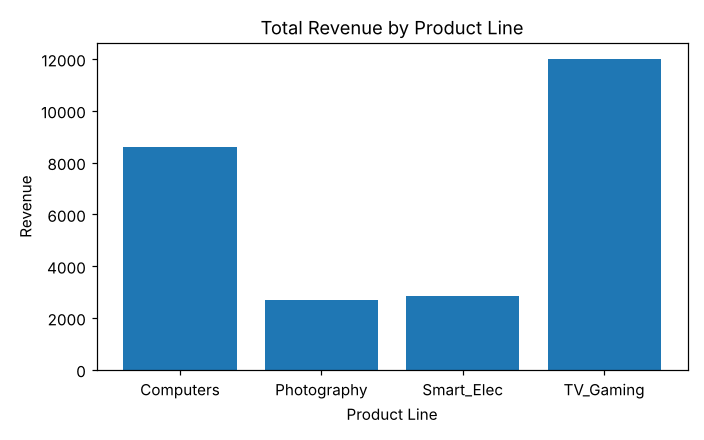

In [13]:
sales_pl = df.groupby("Product_Line")["Revenue"].sum()
plt.bar(sales_pl.index, sales_pl.values)
plt.title("Total Revenue by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Revenue")
plt.show()

### 2. Line chart - revenue of each order

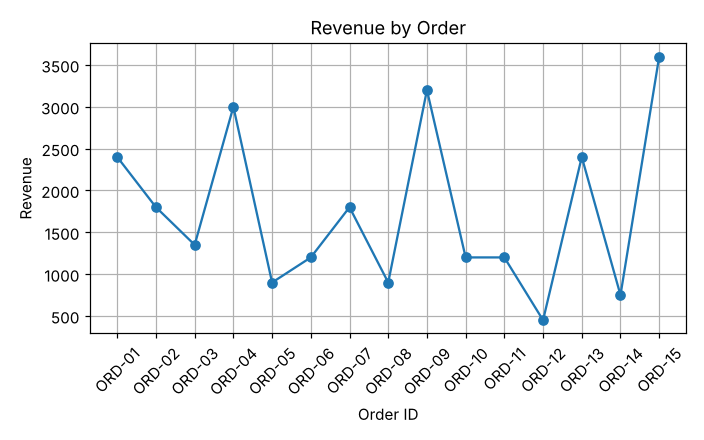

In [14]:
plt.plot(df["Order_ID"], df["Revenue"], marker="o")
plt.title("Revenue by Order")
plt.xlabel("Order ID")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### 3. Histogram - revenue distribution

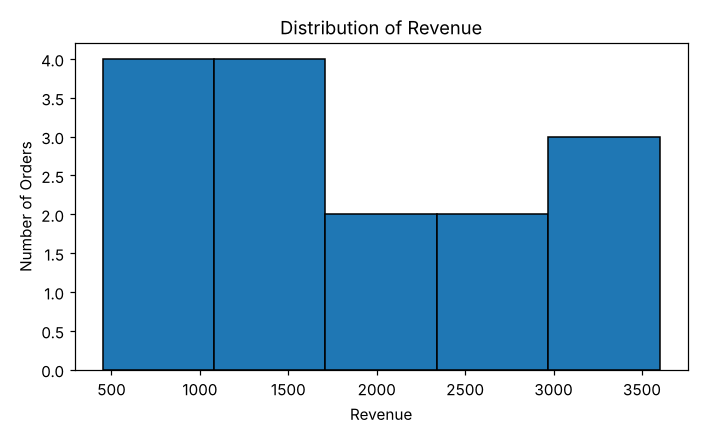

In [15]:
plt.hist(df["Revenue"], bins=5, edgecolor="black")
plt.title("Distribution of Revenue")
plt.xlabel("Revenue")
plt.ylabel("Number of Orders")
plt.show()

### 4. Scatter plot - quantity vs revenue

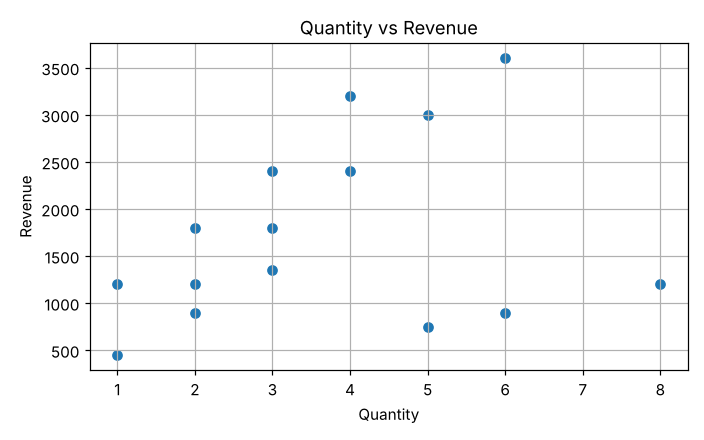

In [16]:
plt.scatter(df["Quantity"], df["Revenue"])
plt.title("Quantity vs Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.grid(True)
plt.show()

### 5. Pie chart - orders by country

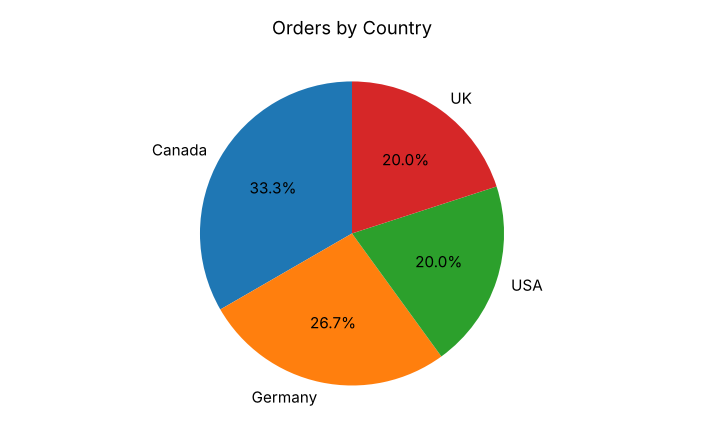

In [17]:
counts = df["Country"].value_counts()
plt.pie(counts.values, labels=counts.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Orders by Country")
plt.show()

## Result

The Pandas DataFrame was successfully created with 15 sample records. Ten pandas operations were performed to display, select, filter, sort, group and analyse the sales data, and five Matplotlib charts were created to visualise it. This helped in understanding how Pandas and Matplotlib are used for data manipulation and analysis in Python.